# 07 – Summary: four particles, eight models

This notebook **trains nothing**: it collects and compares the results saved by notebooks 01–06 (`results/<particle>/export_*.pt`, `*.csv`).

| notebook | model | particles |
|---|---|---|
| 01 | GFlash formula (baseline) | electron, pion, proton |
| 02 | Envelope $r=A\,u^a e^{-bu}$ | electron, pion, proton |
| 03 | Drop $r=A\,g((z'-z_0)/L)$ | electron, pion, proton |
| 04 | Cylinder formula (baseline) | muon |
| 05 | MLP density field + distilled formula (symbolic regression) | all four |
| 06 | CNN (derived architecture) + distilled formula | all four |

**Metric.** Every density model is evaluated on the same test set (15%, stratified per bin) with the per-event negative log-likelihood (NLL, nat/deposit), including detector-cell folding and back-face truncation. Since the test events are the same everywhere, differences can be given with a **paired** standard error.

/home/user/.venv/lib/python3.10/site-packages/nbformat/__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


device: cuda | data: ../../data/simulations/ | output: results


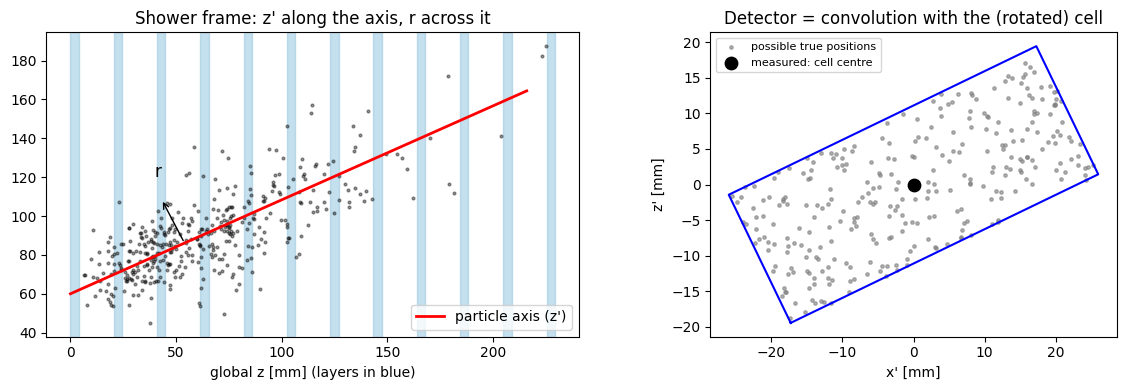

electron  ['cnn', 'cnn_formula', 'gflash', 'mlp', 'mlp_formula']
pion      ['cnn', 'cnn_formula', 'gflash', 'mlp', 'mlp_formula']
proton    ['cnn', 'cnn_formula', 'gflash', 'mlp', 'mlp_formula']
muon      ['cnn', 'cnn_formula', 'cylinder', 'mlp', 'mlp_formula']


In [1]:
DATA_DIR = "../../data/simulations/"
FILE_PATTERN = "regression-{particle}/{particle}_standalone_N100000_M0_20GeV_reg_balanced_s1_v3.csv"
OUT_DIR = "results"
%run -i ./00_common.ipynb
from IPython.display import Markdown, display

PARTICLES = ["electron", "pion", "proton", "muon"]
HU = {"electron": "electron", "pion": "pion", "proton": "proton", "muon": "muon"}
BASE = {"electron": "gflash", "pion": "gflash", "proton": "gflash", "muon": "cylinder"}
MODELS = ["base", "mlp", "mlp_formula", "cnn", "cnn_formula"]
EXP = {p: load_exports(p) for p in PARTICLES}
for p in PARTICLES:
    print(f"{p:9s}", sorted(EXP[p]))

## 1. Accuracy: test NLL relative to the baseline

$\Delta = \mathrm{NLL}_\text{model} - \mathrm{NLL}_\text{baseline}$, with paired SE. Negative value = better than the baseline.

In [2]:
rows = []
for p in PARTICLES:
    base = EXP[p].get(BASE[p])
    for m in MODELS:
        key = BASE[p] if m == "base" else m
        o = EXP[p].get(key)
        if o is None:
            continue
        t = torch.as_tensor(o["test_nll"]).double()
        d = t - torch.as_tensor(base["test_nll"]).double()
        rows.append({"particle": HU[p], "model": key, "params": o["n_params"],
                     "test NLL": t.mean().item(), "SE": (t.std() / len(t) ** .5).item(),
                     "Δ vs baseline": d.mean().item(), "Δ SE (paired)": (d.std() / len(d) ** .5).item()})
ACC = pd.DataFrame(rows)
display(ACC.style.format({"test NLL": "{:.4f}", "SE": "{:.4f}", "Δ vs baseline": "{:+.4f}", "Δ SE (paired)": "{:.4f}"}).hide(axis="index"))
ACC.to_csv(f"{OUT_DIR}/summary_accuracy.csv", index=False)

particle,model,params,test NLL,SE,Δ vs baseline,Δ SE (paired)
electron,gflash,33,14.8479,0.0101,+0.0000,0.0000
electron,mlp,2785,14.8068,0.0100,-0.0411,0.0010
electron,mlp_formula,19,14.8516,0.0121,+0.0037,0.0028
electron,cnn,336355,14.8076,0.0099,-0.0403,0.0010
electron,cnn_formula,19,14.8526,0.0119,+0.0046,0.0027
pion,gflash,27,18.1563,0.0120,+0.0000,0.0000
pion,mlp,3841,18.1221,0.0121,-0.0342,0.0011
pion,mlp_formula,21,18.1634,0.0120,+0.0071,0.0009
pion,cnn,121939,18.1218,0.0121,-0.0345,0.0011
pion,cnn_formula,21,18.1617,0.0120,+0.0054,0.0007


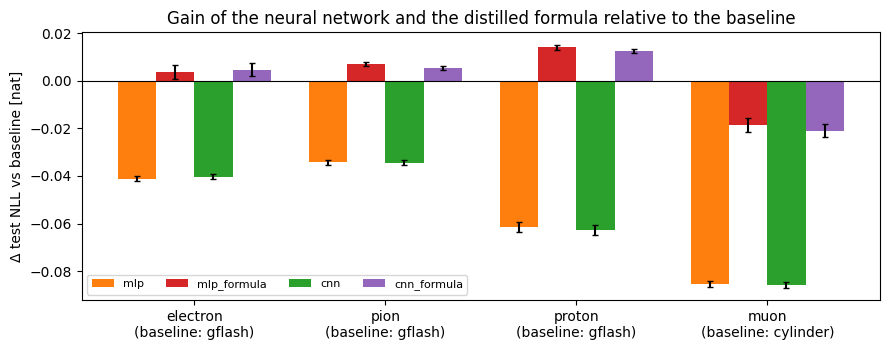

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
names = [m for m in ["mlp", "mlp_formula", "cnn", "cnn_formula"]]
w = 0.2
for k, m in enumerate(names):
    sub = ACC[ACC.model == m].set_index("particle").reindex([HU[p] for p in PARTICLES])
    x = np.arange(len(PARTICLES)) + (k - 1.5) * w
    ax.bar(x, sub["Δ vs baseline"], w, yerr=sub["Δ SE (paired)"], color=COLORS[m], label=m, capsize=2)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(np.arange(len(PARTICLES)), [f"{HU[p]}\n(baseline: {BASE[p]})" for p in PARTICLES])
ax.set_ylabel("Δ test NLL vs baseline [nat]"); ax.legend(fontsize=8, ncol=4)
ax.set_title("Gain of the neural network and the distilled formula relative to the baseline")
plt.tight_layout(); plt.show()

**Interpretation.**
- The neural density fields (MLP, CNN) are below the baseline for every particle; this is an upper estimate of "how much information is left in the data".
- The distilled formula is **better than the baseline only for the muon** (cylinder, ≈ −0.02 nat, approx. 7 SE). For the electron it is statistically equivalent to GFlash (+0.004 ± 0.003); for the pion (+0.005–0.007) and proton (+0.013–0.014) it is significantly worse. The network's excess (0.03–0.09 nat) therefore **cannot** be expressed in closed form with the formula families studied; distillation reaches at most the baseline level, because the KL fit to the network map is not the same as optimising the data NLL.
- The formulas distilled from the MLP and from the CNN are practically identical (≤0.002 nat difference): the result of distillation does not depend on which network it starts from.
- The difference between MLP and CNN is negligible compared with the distance from the baseline: the task (a smooth 2D (z', r) density parametrised in ln p) does not require a convolutional inductive bias.

## 2. Architecture justification

### 2a. MLP (05): width search, then depth search, 1-SE rule

In [4]:
for p in PARTICLES:
    f = f"{OUT_DIR}/{p}/mlp_architecture.csv"
    if not os.path.exists(f):
        continue
    t = pd.read_csv(f).drop_duplicates("config", keep="last")
    ch = t[t.chosen == "◀"].iloc[-1]
    print(f"{HU[p]:9s} selected: {ch.config:9s} ({int(ch.params)} params) | "
          f"spread of val NLL across candidates: {t['val NLL'].max() - t['val NLL'].min():.4f} nat")

electron  selected: L3xH32    (2785 params) | spread of val NLL across candidates: 0.0025 nat
pion      selected: L4xH32    (3841 params) | spread of val NLL across candidates: 0.0013 nat
proton    selected: L3xH16    (881 params) | spread of val NLL across candidates: 0.0115 nat
muon      selected: L3xH32    (2785 params) | spread of val NLL across candidates: 0.0025 nat


### 2b. CNN (06): derived architecture + capacity check against the MLP

In [5]:
caps = []
for p in PARTICLES:
    f = f"{OUT_DIR}/{p}/cnn_capacity.csv"
    if os.path.exists(f):
        t = pd.read_csv(f).rename(columns={"Unnamed: 0": "configuration"}); t.insert(0, "particle", HU[p]); caps.append(t)
if caps:
    display(pd.concat(caps).style.format(precision=4).hide(axis="index"))

particle,configuration,params,train NLL,val NLL,train−val,MLP val NLL,Δ vs MLP,SE,sufficient
electron,"CNN (48, 48, 32, 32, 16)",121939,14.7939,14.7899,0.0040,14.7884,0.0016,0.0002,False
electron,"CNN (96, 96, 64, 64, 32)",336355,14.7935,14.7893,0.0041,14.7884,0.0009,0.0003,False
pion,"CNN (48, 48, 32, 32, 16)",121939,18.1078,18.1185,-0.0107,18.1191,-0.0006,0.0003,True
proton,"CNN (48, 48, 32, 32, 16)",121939,18.1734,18.1950,-0.0216,18.1958,-0.0008,0.0005,True
muon,"CNN (48, 48, 32, 32, 16)",121939,15.9991,16.0019,-0.0027,16.0025,-0.0007,0.0003,True


CNN capacity criterion: the validation NLL should be within 1 SE of the MLP's. For the pion, proton and muon the base architecture satisfies this. For the electron it is **formally not satisfied**, but: the shortfall (≈10⁻³ nat) is smaller than the spread among the MLP candidates, and the two networks practically agree in test NLL as well. So the CNN is not better not because of capacity, but because the MLP is already sufficient for the target function.

## 3. The extracted formulas

In [6]:
for p in PARTICLES:
    display(Markdown(f"---\n## {HU[p]}"))
    for key in [BASE[p], "mlp_formula", "cnn_formula"]:
        o = EXP[p].get(key)
        if o is not None and o.get("formula"):
            display(Markdown(o["formula"]))

---
## electron

### GFlash (elektron baseline)

$$L \propto s^{\alpha-1}e^{-(\alpha-1)s/t_{max}},\; s=z'-z_0,\; \alpha=1+e^{\mathrm{log\_am1}},\; t_{max}=e^{\mathrm{log\_tmax}}$$

$$T = \frac{p_c}{\pi}\frac{R_C^2}{(r^2+R_C^2)^2}+\frac{1-p_c}{\pi}\frac{R_T^2}{(r^2+R_T^2)^2}$$

| parameter | value, $L=(\ln(p/\mathrm{GeV}) +0.7609)/3.757$ | depth slope (× z'/1000) |
|---|---|---|
| `z0` | $-15.21 +5.797\,L -1.624\,L^2 -1.35\,L^3 +0.6446\,L^4$ | – |
| `log_tmax` | $+3.91 +1.369\,L -0.6749\,L^2 -0.003854\,L^3 +0.02245\,L^4$ | – |
| `log_am1` | $-0.3275 -0.09391\,L +0.3962\,L^2 -0.2607\,L^3 +0.09396\,L^4$ | – |
| `log_rc` | $+2.664 -0.2264\,L -0.2412\,L^2 +0.392\,L^3 -0.1934\,L^4$ | +3.293 |
| `log_ratio` | $+8.556 +0.02095\,L -0.4767\,L^2 -0.04249\,L^3 +0.08896\,L^4$ | -6.595 |
| `logit_pc` | $-2.135 +2.836\,L +1.438\,L^2 -0.05146\,L^3 -0.3319\,L^4$ | -10.68 |

Number of parameters: **33**

### MLP → formula (electron)

$$L \propto \sigma\!\left(\frac{z'-z_s}{w_1}\right)\sigma\!\left(\frac{\ell-z'}{w_2}\right)e^{\kappa z'/1000}$$

$$T = p_c\frac{e^{-r^2/2\sigma^2}}{2\pi\sigma^2}+(1-p_c)\frac{e^{-r/\lambda}}{2\pi\lambda^2}$$

| parameter | value, $L=\ln(p/\mathrm{GeV})$ | depth slope (× z'/1000) |
|---|---|---|
| `zs` | $-5.543 +0.8709\,L$ | – |
| `log_w1` | $+0.8955 +0.1409\,L$ | – |
| `log_ell` | $+3.591 +0.2161\,L$ | – |
| `log_w2` | $+4.165 -0.1755\,L$ | – |
| `kappa` | $-1.649 +5.255\,L$ | – |
| `log_sig` | $+2.512 -0.04294\,L$ | +3.105 |
| `log_lam` | $+3.197 +0.004556\,L$ | +3.572 |
| `logit_pc` | $+2.513 +0.3291\,L$ | -6.332 |

Number of parameters: **19**

### CNN → formula (electron)

$$L \propto \sigma\!\left(\frac{z'-z_s}{w_1}\right)\sigma\!\left(\frac{\ell-z'}{w_2}\right)e^{\kappa z'/1000}$$

$$T = p_c\frac{e^{-r^2/2\sigma^2}}{2\pi\sigma^2}+(1-p_c)\frac{e^{-r/\lambda}}{2\pi\lambda^2}$$

| parameter | value, $L=\ln(p/\mathrm{GeV})$ | depth slope (× z'/1000) |
|---|---|---|
| `zs` | $-5.987 +0.6733\,L$ | – |
| `log_w1` | $+0.871 +0.07453\,L$ | – |
| `log_ell` | $+3.496 +0.2426\,L$ | – |
| `log_w2` | $+4.193 -0.1865\,L$ | – |
| `kappa` | $-1.939 +5.511\,L$ | – |
| `log_sig` | $+2.555 -0.05617\,L$ | +3.176 |
| `log_lam` | $+3.406 -0.03827\,L$ | +3.413 |
| `logit_pc` | $+2.799 +0.2914\,L$ | -7.08 |

Number of parameters: **19**

---
## pion

### GFlash (pion baseline)

$$L \propto s^{\alpha-1}e^{-(\alpha-1)s/t_{max}},\; s=z'-z_0,\; \alpha=1+e^{\mathrm{log\_am1}},\; t_{max}=e^{\mathrm{log\_tmax}}$$

$$T = \frac{p_c}{\pi}\frac{R_C^2}{(r^2+R_C^2)^2}+\frac{1-p_c}{\pi}\frac{R_T^2}{(r^2+R_T^2)^2}$$

| parameter | value, $L=(\ln(p/\mathrm{GeV}) -0.2912)/2.705$ | depth slope (× z'/1000) |
|---|---|---|
| `z0` | $-20.71 -3.613\,L +9.392\,L^2 +0.9912\,L^3$ | – |
| `log_tmax` | $+4.192 +1.182\,L -0.903\,L^2 +0.4643\,L^3$ | – |
| `log_am1` | $-0.8632 -0.2769\,L +0.7155\,L^2 -0.3645\,L^3$ | – |
| `log_rc` | $+3.181 +0.226\,L -0.7617\,L^2 +0.5568\,L^3$ | +0.9312 |
| `log_ratio` | $+0.9186 -0.7144\,L +0.2603\,L^2 +0.3279\,L^3$ | +0.7853 |
| `logit_pc` | $+0.2552 -2.195\,L +2.917\,L^2 -0.9196\,L^3$ | +0.3919 |

Number of parameters: **27**

... (6 outputs left out)

---
## muon

### Cylinder (muon baseline)

$$L \propto \sigma\!\left(\frac{z'-z_s}{w_1}\right)\sigma\!\left(\frac{\ell-z'}{w_2}\right)e^{\kappa z'/1000}$$

$$T = \frac{p_c}{\pi}\frac{R_C^2}{(r^2+R_C^2)^2}+\frac{1-p_c}{\pi}\frac{R_T^2}{(r^2+R_T^2)^2}$$

| parameter | value, $L=(\ln(p/\mathrm{GeV}) -0.04485)/2.951$ | depth slope (× z'/1000) |
|---|---|---|
| `zs` | $-8.098 -1.465\,L -0.3256\,L^2 +2.618\,L^3 -1.679\,L^4 +0.3169\,L^5 -0.4709\,L^6$ | – |
| `log_w1` | $+0.6189 -0.6606\,L +1.442\,L^2 +0.4047\,L^3 -1.489\,L^4 -0.2043\,L^5 -0.1322\,L^6$ | – |
| `log_ell` | $+6.876 +3.499\,L -0.7892\,L^2 +0.09207\,L^3 -5.981\,L^4 +10.31\,L^5 -5.203\,L^6$ | – |
| `log_w2` | $+3.148 +2.921\,L +1.645\,L^2 -2.293\,L^3 +0.04441\,L^4 -0.1571\,L^5 +0.3984\,L^6$ | – |
| `kappa` | $-0.9399 -0.6789\,L +1.95\,L^2 -1.061\,L^3 -0.5191\,L^4 +0.2432\,L^5 +0.1223\,L^6$ | – |
| `log_rc` | $+2.255 +0.7257\,L +0.4558\,L^2 -1.522\,L^3 +0.1157\,L^4 +0.6556\,L^5 -0.1115\,L^6$ | +0.2207 |
| `log_ratio` | $-0.807 -4.92\,L -6.641\,L^2 +8.222\,L^3 +6.771\,L^4 -16.38\,L^5 -1.811\,L^6$ | +2.767 |
| `logit_pc` | $+6.248 -0.6351\,L -0.4952\,L^2 +6.143\,L^3 +3.516\,L^4 -3.727\,L^5 -0.244\,L^6$ | -182.6 |

Number of parameters: **59**

### MLP → formula (muon)

$$L \propto \sigma\!\left(\frac{z'-z_s}{w_1}\right)\sigma\!\left(\frac{\ell-z'}{w_2}\right)e^{\kappa z'/1000}$$

$$T = p_c\frac{e^{-r^2/2\sigma^2}}{2\pi\sigma^2}+(1-p_c)\frac{e^{-r/\lambda}}{2\pi\lambda^2}$$

| parameter | value, $L=\ln(p/\mathrm{GeV})$ | depth slope (× z'/1000) |
|---|---|---|
| `zs` | $-6.926 -0.2666\,L +0.05593\,L^2$ | – |
| `log_w1` | $+0.4087 -0.02544\,L +0.01252\,L^2$ | – |
| `log_ell` | $+6.784 +1.253\,L -0.07682\,L^2$ | – |
| `log_w2` | $+3.066 +0.504\,L +0.1327\,L^2$ | – |
| `kappa` | $-0.7226 -0.2105\,L +0.06371\,L^2$ | – |
| `log_sig` | $+2.751 -0.1166\,L +0.01357\,L^2$ | +0.3901 |
| `log_lam` | $+2.033 -0.3814\,L +0.3452\,L^2$ | +1.809 |
| `logit_pc` | $-0.06678 +3.41\,L -0.1878\,L^2$ | -2.275 |

Number of parameters: **27**

### CNN → formula (muon)

$$L \propto \sigma\!\left(\frac{z'-z_s}{w_1}\right)\sigma\!\left(\frac{\ell-z'}{w_2}\right)e^{\kappa z'/1000}$$

$$T = p_c\frac{e^{-r^2/2\sigma^2}}{2\pi\sigma^2}+(1-p_c)\frac{e^{-r/\lambda}}{2\pi\lambda^2}$$

| parameter | value, $L=\ln(p/\mathrm{GeV})$ | depth slope (× z'/1000) |
|---|---|---|
| `zs` | $-6.681 -0.1706\,L +0.03626\,L^2$ | – |
| `log_w1` | $+0.4486 -0.005125\,L +0.01379\,L^2$ | – |
| `log_ell` | $+6.788 +1.224\,L -0.08603\,L^2$ | – |
| `log_w2` | $+2.82 +0.4953\,L +0.1394\,L^2$ | – |
| `kappa` | $-0.7856 -0.2151\,L +0.07867\,L^2$ | – |
| `log_sig` | $+2.77 -0.1377\,L +0.01656\,L^2$ | +0.4084 |
| `log_lam` | $+2.015 -0.3167\,L +0.3412\,L^2$ | +1.816 |
| `logit_pc` | $+0.3003 +3.598\,L -0.3817\,L^2$ | -2.423 |

Number of parameters: **27**

## 4. Profiles from the models

Longitudinal $dE/dz'$ and lateral $dE/dr$ profiles at two momenta, from every model (from the exported maps, not from the data).

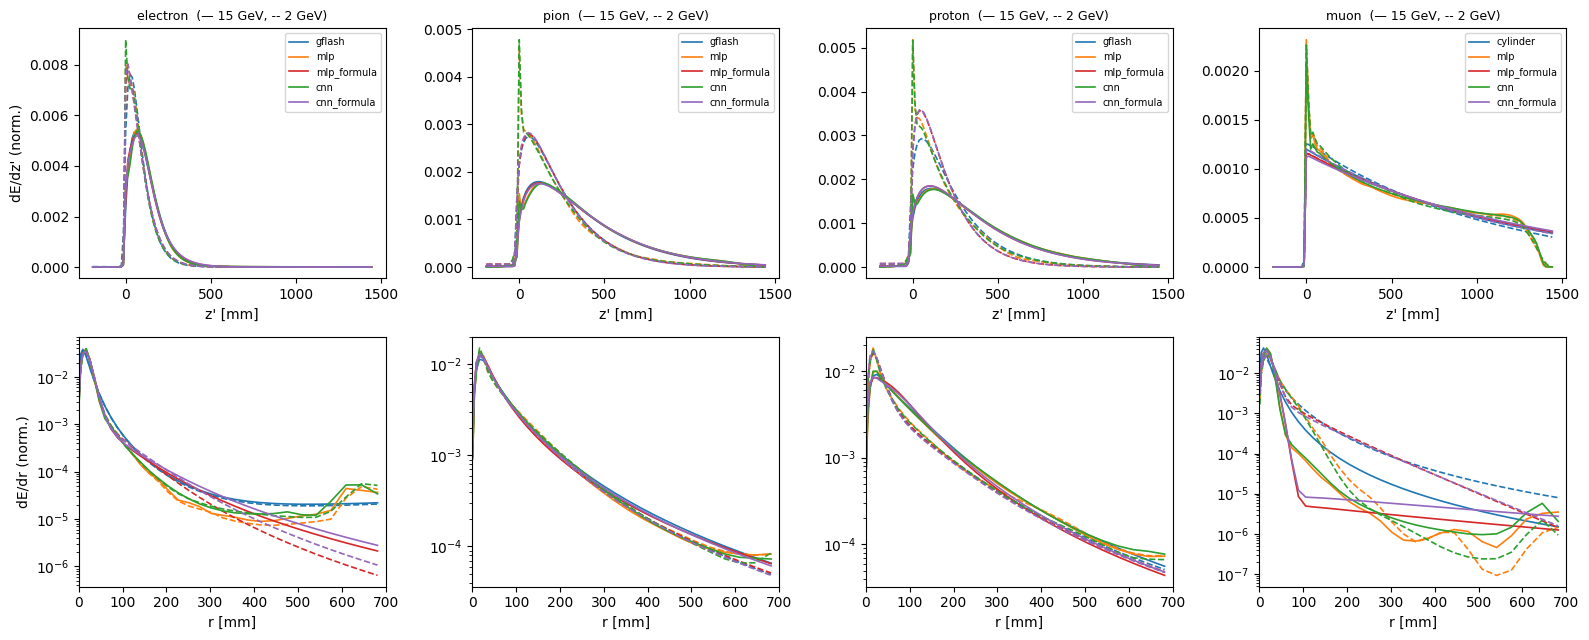

In [7]:
ze, re_ = Z_EDGES.cpu().numpy(), R_EDGES.cpu().numpy()
zc, rc = 0.5 * (ze[1:] + ze[:-1]), 0.5 * (re_[1:] + re_[:-1])
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for j, p in enumerate(PARTICLES):
    for key in [BASE[p], "mlp", "mlp_formula", "cnn", "cnn_formula"]:
        o = EXP[p].get(key)
        if o is None:
            continue
        m = TableModel(o)
        for pv, ls in ((2.0, "--"), (15.0, "-")):
            P = m(torch.log(torch.tensor([pv], device=DEVICE))).exp()[0].cpu().numpy()
            axes[0, j].plot(zc, P.sum(1) / np.diff(ze), ls, color=COLORS[key], lw=1.2, label=key if pv == 15 else None)
            axes[1, j].plot(rc, P.sum(0) / np.diff(re_), ls, color=COLORS[key], lw=1.2)
    axes[0, j].set_title(f"{HU[p]}  (— 15 GeV, -- 2 GeV)", fontsize=9); axes[0, j].set_xlabel("z' [mm]")
    axes[1, j].set_yscale("log"); axes[1, j].set_xlabel("r [mm]"); axes[1, j].set_xlim(0, 700)
    axes[0, j].legend(fontsize=7)
axes[0, 0].set_ylabel("dE/dz' (norm.)"); axes[1, 0].set_ylabel("dE/dr (norm.)")
plt.tight_layout(); plt.show()

## 5. Density maps (MLP), per particle

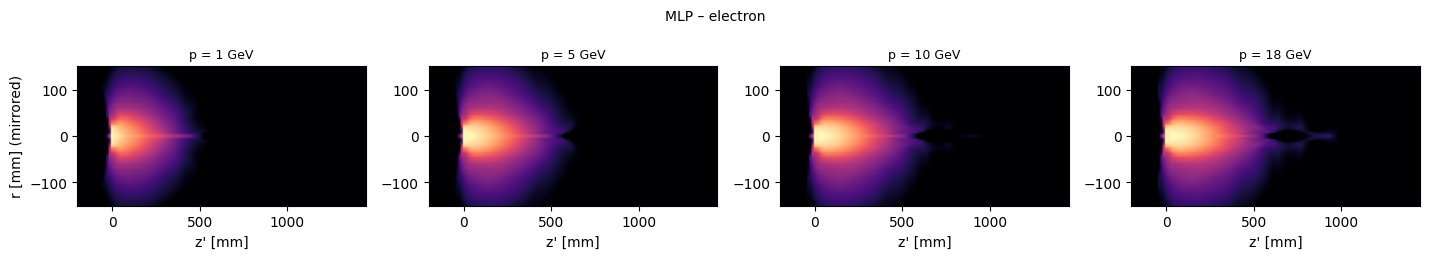

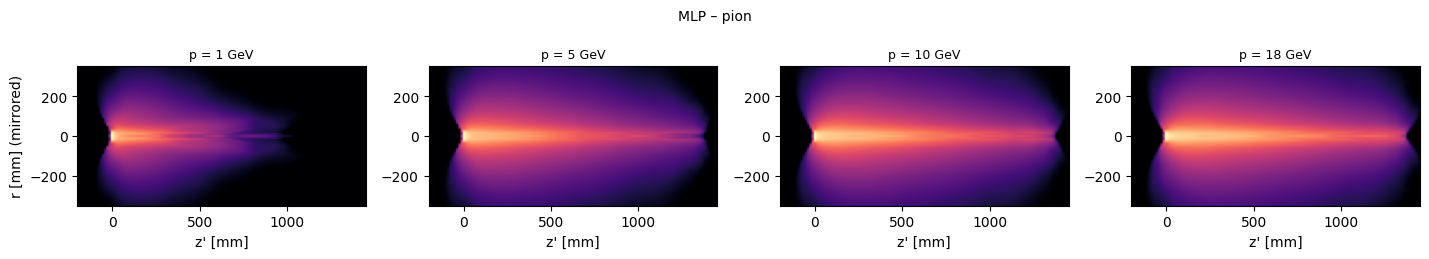

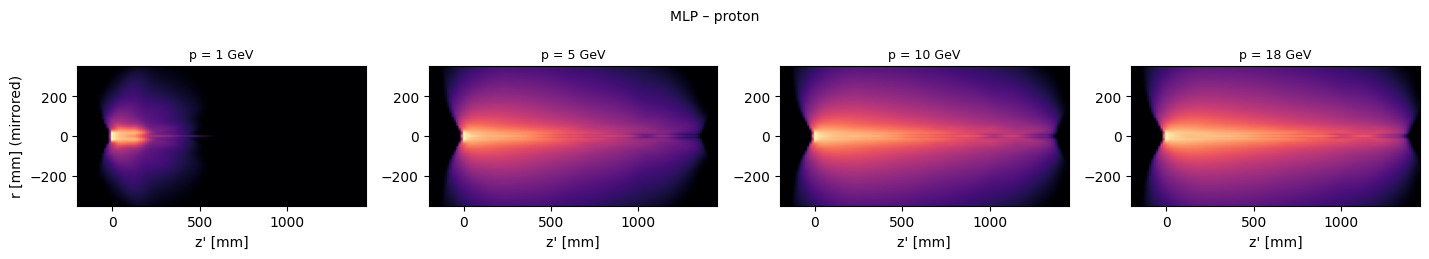

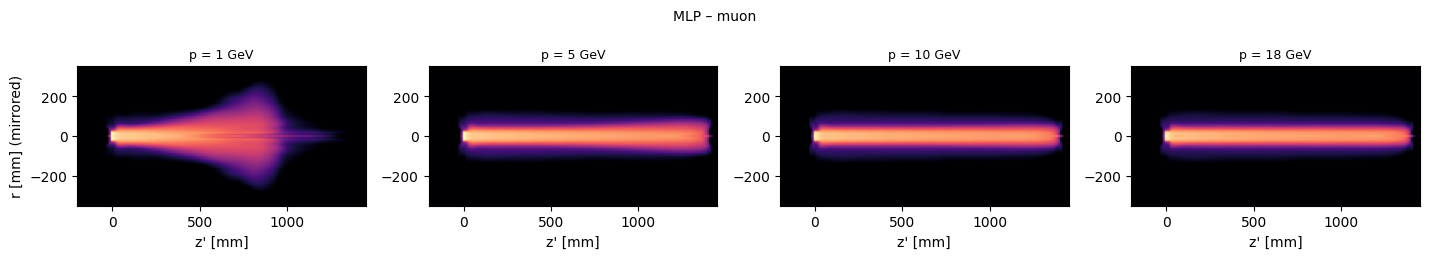

In [8]:
for p in PARTICLES:
    if "mlp" in EXP[p]:
        shape_map(TableModel(EXP[p]["mlp"]), title=f"MLP – {HU[p]}", r_show=150 if p == "electron" else 350)

## 6. Shapes: volume and coverage with the same metric

From the uniform comparison in notebooks 05/06 (`comparison_*shapes.csv`): per bin, the percentage of test showers that stay inside the shape (with ≥95% of their energy), and the volume of the shape.

**Important:** the envelope and the drop are explicitly sized for the "≥95% energy in 98% of showers" criterion; the `r95` shapes (GFlash/cylinder/MLP/CNN) are the 95% isolines of the *mean* map, so their coverage is lower and their volume smaller – they do not serve the same purpose. The envelope/drop volume is analytic; the r95 volume is summed on the grid.

particle,formula,V_L,r_max,coverage
electron,GFlash r95,9.0,97,0.850
electron,MLP r95,5.7,81,0.456
electron,MLP-formula r95,6.7,82,0.578
electron,CNN r95,6.1,82,0.558
electron,CNN-formula r95,7.6,83,0.693
electron,envelope,26.5,154,0.978
electron,drop,26.1,148,0.977
pion,GFlash r95,446.8,396,0.783
pion,MLP r95,402.9,384,0.772
pion,MLP-formula r95,479.4,398,0.808


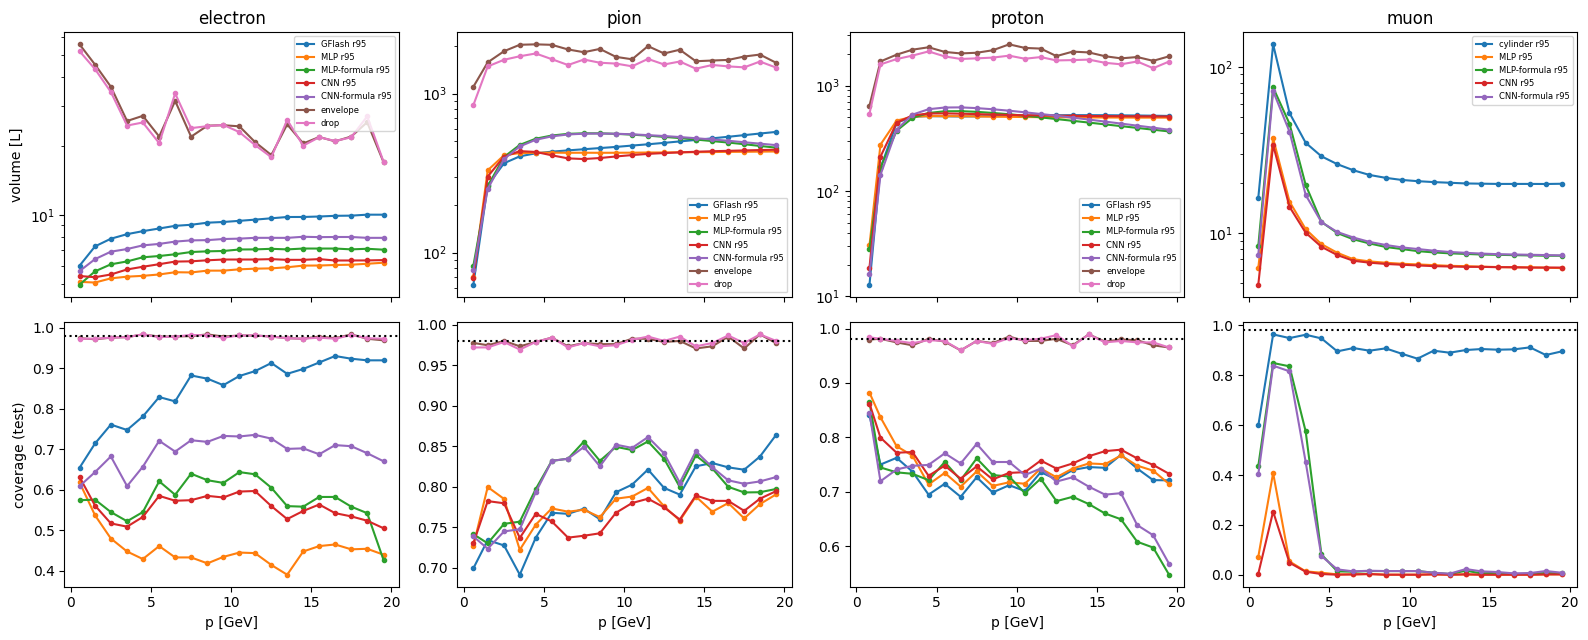

In [9]:
cmp = []
for p in PARTICLES:
    for f in ("comparison_7shapes.csv", "comparison_5shapes.csv"):
        path = f"{OUT_DIR}/{p}/{f}"
        if os.path.exists(path):
            t = pd.read_csv(path); t.insert(0, "particle", HU[p]); cmp.append(t); break
CMP = pd.concat(cmp)
SUM = CMP.groupby(["particle", "formula"], sort=False).agg(V_L=("V_L", "mean"), r_max=("r_max", "mean"), coverage=("cov_test", "mean")).reset_index()
display(SUM.style.format({"V_L": "{:.1f}", "r_max": "{:.0f}", "coverage": "{:.3f}"}).hide(axis="index"))
SUM.to_csv(f"{OUT_DIR}/summary_shapes.csv", index=False)

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True)
for j, p in enumerate(PARTICLES):
    t = CMP[CMP.particle == HU[p]]
    for name, g in t.groupby("formula", sort=False):
        axes[0, j].plot(g.p_mean, g.V_L, "o-", ms=3, label=name)
        axes[1, j].plot(g.p_mean, g.cov_test, "o-", ms=3)
    axes[0, j].set_title(HU[p]); axes[0, j].set_yscale("log"); axes[1, j].axhline(0.98, color="k", ls=":")
    axes[1, j].set_xlabel("p [GeV]"); axes[0, j].legend(fontsize=6)
axes[0, 0].set_ylabel("volume [L]"); axes[1, 0].set_ylabel("coverage (test)")
plt.tight_layout(); plt.show()

## 7. **Open caveats**

1. **Grid boundary for hadrons:** `R_MAX = 700 mm`, `Z_MAX = 1450 mm`; the pion/proton envelope and drop ($r_{max}$ ≈ 700–780 mm, ~1500–1700 L) reach it, so there the shape is clipped by the grid.
2. **r95 vs. 98% criterion:** the shapes derived from the density models are not calibrated to the envelope criterion (see section 6); a fair comparison would need a per-bin calibrated iso-level.
3. The smoothing penalty acts only along z' and on the log-probability.
4. The envelopes smoothed in ln p were not validated on a separate test set.
5. The back-face plane is approximate (distance taken along the axis).
6. Some per-bin fits sit at the search boundary (e.g. proton bin 2: $z_0 \approx -200$).
7. Due to the flat validation curves the 1-SE rule is close to argmin; the MLP search is greedy (first width, then depth).
8. Notebook 05 uses the mean p of the test bin, 03 the mean training p; there is no ln p centring in the distillation.
9. CNN: for the pion, proton and muon the base architecture passed the capacity check (val NLL below the MLP); for the electron formally not (≈10⁻³ nat shortfall relative to the MLP), not even after doubling the channels.